# The reference beam as a trainable layer: playing VizDoom

Digital twin of the off-axis holography bench. A game frame is written as phase on the object arm of the SLM and
scrambled by the diffuser; a trained reference pattern $E$ on the reference arm interferes with it on the camera, and
three fixed detectors read the action. The diffuser is never modelled: the object fields of the data set are measured
**once** with a flat reference, and $E$ is trained **offline** on them through a model of the reference arm only.

| Section | In the manuscript |
|---|---|
| 1 · One frame, two reads | Eq. (7); Methods "Offline training of the reference arm"; Supplementary Note 4B |
| 2 · The reference-arm model | Supplementary Note 4A, Eq. (S14), Fig. S3a |
| 3 · VizDoom *Basic*: offline training, demodulated read, digital baselines, closed loop | Fig. 3b,c; Supplementary Note 4B, Fig. S3b |
| 4 · *Defend the Center*: all-optical read, kills per episode, the bench's detector offsets | Fig. 3d; Supplementary Note 4B |

The optics are in [`twin.py`](../Object/twin.py) (Object folder) and the reference arm, the two-arm bench and the
offline training in [`reference.py`](reference.py). The twin is set like the bench build of the article runs: light
levels, interference visibility, five exposures per read, the accuracy of the reference-arm model, the detector layout,
the training recipe, the game build (VizDoom 1.3.1) and the closed-loop seeds. **On Colab:** upload `twin.py` and `reference.py` to the working
directory (and, to skip generating the game frames, `vizdoom_basic.npz` and `vizdoom_defend_the_center.npz` from
`data/`); the first cell installs VizDoom. Runtime about 20 min on a laptop CPU.

In [1]:
import os
import sys
import time
import importlib.util
import subprocess

import importlib.metadata
try:
    vizdoom_version = importlib.metadata.version("vizdoom")
except importlib.metadata.PackageNotFoundError:
    vizdoom_version = None
if vizdoom_version != "1.3.1":                                    # the bench's VizDoom build (e.g. on Colab)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "vizdoom==1.3.1"], check=True, capture_output=True)
sys.path.append(os.path.join("..", "Object"))                    # twin.py; on Colab it sits next to this notebook

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import Image, display
import vizdoom as vzd
import twin as tw
import reference as ref

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.titlesize": 9})
DATA = os.path.join("..", "data") if os.path.isdir(os.path.join("..", "data")) else "."
os.makedirs("gifs", exist_ok=True)
T_START = time.time()

## 1 · One frame, two reads

The camera records $I = |O + R|^2$ with the reference tilted by the carrier $\mathbf f_c$. A raw frame holds
$|O|^2 + |R|^2 + OR^* + O^*R$; only $OR^*$ carries the product of the two arms. It is read in two ways from the same
frame:

* **fringe-matched read** (Eq. 7): each detector is a window $M_c$ multiplied by the fringe $e^{j2\pi\mathbf f_c\cdot\mathbf x}$
  and summed over the raw frame. This moves $OR^*$ to zero frequency, while $|O|^2$, $|R|^2$ and $O^*R$ oscillate under the
  window and cancel, so $s_c \cong \mathrm{Re}\sum_{\mathbf x\in M_c}OR^*$, with no Fourier transform;
* **demodulated read**: the sideband $d = OR^*$ is cut out of the spectrum and summed over the same windows.

Three square detectors (24 × 24 field pixels, 6 pixels apart, the bench's layout) form a triangle on the 90 × 90
readout window. Below, one frame with a
random reference, and the two reads of 64 random inputs.

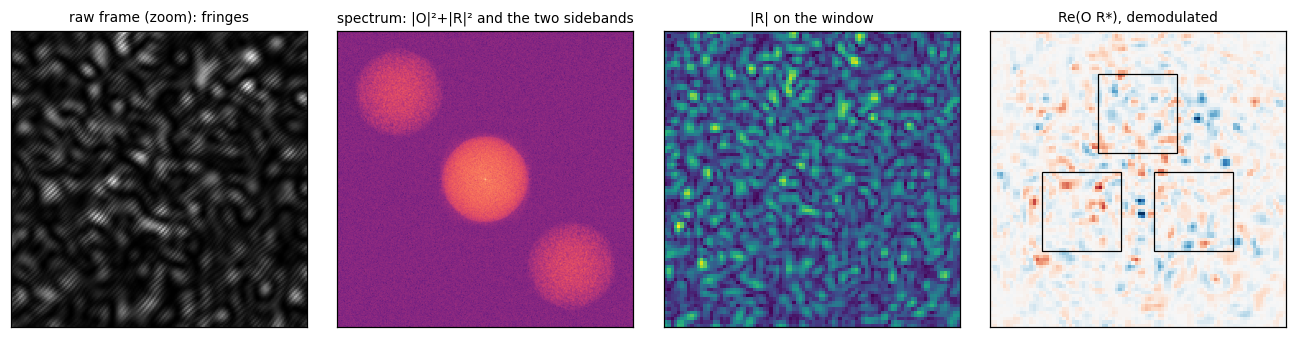

correlation of fringe-matched and demodulated scores over 64 reads, per detector: 0.9937, 0.9958, 0.9967


In [2]:
bench = ref.Bench(seed=0)
det = ref.Detectors([(13, 33), (43, 16), (43, 50)], size=24)               # LEFT, RIGHT, ATTACK
rng = np.random.default_rng(0)
E_random = 0.8 * np.exp(2j * np.pi * rng.random((ref.NE, ref.NE)))
frame = bench.frame(rng.uniform(0, np.pi, (1, tw.NC, tw.NC)), E_random)[0]
d = ref.demodulate(frame)

c, z = ref.NU // 2, 90
fig, ax = plt.subplots(1, 4, figsize=(12, 3))
ax[0].imshow(frame[c - z:c + z, c - z:c + z], cmap="gray"); ax[0].set_title("raw frame (zoom): fringes")
ax[1].imshow(np.log10(np.abs(np.fft.fftshift(np.fft.fft2(frame)))**2 + 1), cmap="magma")
ax[1].set_title("spectrum: |O|²+|R|² and the two sidebands")
ax[2].imshow(np.abs(ref.MODEL.forward(E_random)[ref.W90, ref.W90]), cmap="viridis"); ax[2].set_title("|R| on the window")
v = np.abs(np.real(d[ref.W90, ref.W90])).max()
ax[3].imshow(np.real(d[ref.W90, ref.W90]), cmap="RdBu_r", vmin=-v, vmax=v); ax[3].set_title("Re(O R*), demodulated")
for k, (r, cc) in enumerate(det.corners):
    ax[3].add_patch(Rectangle((cc - 0.5, r - 0.5), det.size, det.size, fill=False, color="k", lw=0.8))
for a in ax: a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

raw, demod = bench.read(rng.uniform(0, np.pi, (64, tw.NC, tw.NC)), E_random, det)
print("correlation of fringe-matched and demodulated scores over 64 reads, per detector:",
      ", ".join(f"{np.corrcoef(raw[:, k], demod[:, k])[0, 1]:.4f}" for k in range(3)))

## 2 · The reference-arm model

The reference arm bypasses the diffuser, so its adjoint needs only a model of its own free-space path: the
illumination, the SLM cells, a pupil (iris, defocus, aberrations) and a shift onto the camera, described by a few
parameters (SI Eq. S14, `ref.ReferenceArm`). The twin's model differs from its hidden true arm by a defocus error,
small astigmatism and coma and a sub-pixel shift. For *Basic* the true arm is the model itself: the bench
refitted its reference model at each session, and in the *Basic* session the refitted model took the same decision as
the hardware on 98 % of the test frames. As on the bench (Fig. S3a), its **model accuracy** is the correlation
between predicted and measured interference $\hat O R^*$ for random reference patterns, against the repeatability of the
measurement. The model is linear in $E$, so the adjoint is checked against the inner product.

In [3]:
E_test = np.exp(2j * np.pi * rng.random((ref.NE, ref.NE)))
R_test = rng.standard_normal((tw.N, tw.N)) + 1j * rng.standard_normal((tw.N, tw.N))
lhs, rhs = np.vdot(ref.MODEL.forward(E_test), R_test), np.vdot(E_test, ref.MODEL.adjoint(R_test))
print(f"adjoint of the reference model: relative error {abs(lhs - rhs) / abs(lhs):.1e}")

x = rng.uniform(0, np.pi, (1, tw.NC, tw.NC))
O_hat = bench.acquire(np.repeat(x, 5, axis=0)).mean(0)          # the object field, flat reference, five reads
accuracy, repeat = [], []
for _ in range(20):
    E = np.exp(2j * np.pi * rng.random((ref.NE, ref.NE))) * rng.uniform(0.3, 1, (ref.NE, ref.NE))
    d1, d2 = ref.demodulate(bench.frame(np.repeat(x, 2, axis=0), E))[:, ref.W90, ref.W90]
    predicted = (O_hat * np.conj(ref.MODEL.forward(E)))[ref.W90, ref.W90]
    accuracy.append(tw.corr(predicted, d1)); repeat.append(tw.corr(d1, d2))
print(f"reference model accuracy {np.mean(accuracy):.3f} against a repeatability of {np.mean(repeat):.3f} "
      f"(20 random references; bench: 0.85 against 0.96)")

adjoint of the reference model: relative error 4.2e-15


reference model accuracy 0.973 against a repeatability of 0.996 (20 random references; bench: 0.85 against 0.96)


## 3 · VizDoom *Basic*

A Cacodemon floats somewhere on the opposite wall; the player strafes left or right and shoots.

* **Frames and labels.** A noisy oracle plays (mostly the oracle's action, sometimes random ones); every frame with the
  monster is stored with the oracle's action: ATTACK if the monster is within 3.5 px of the centre, else move toward it.
  Near-duplicate frames are dropped and the episodes are split into training, validation and test sets (80/10/10).
* **Encoding** (a fixed colour projection and pooling, no learned features): the 32 rows where the monster appears are
  projected on "magenta" ($R + B - 2G$), pooled in 1 × 5 blocks to $32\times32$ values $v$, and written as phase
  $\varphi = \pi v/255$ on the object cells.

The frames are cached in `vizdoom_basic.npz`; if the file is missing, VizDoom generates it (a few minutes).

9996 frames; training / validation / test = 7824 / 1019 / 1153; LEFT / RIGHT / ATTACK = [4829, 4207, 960]


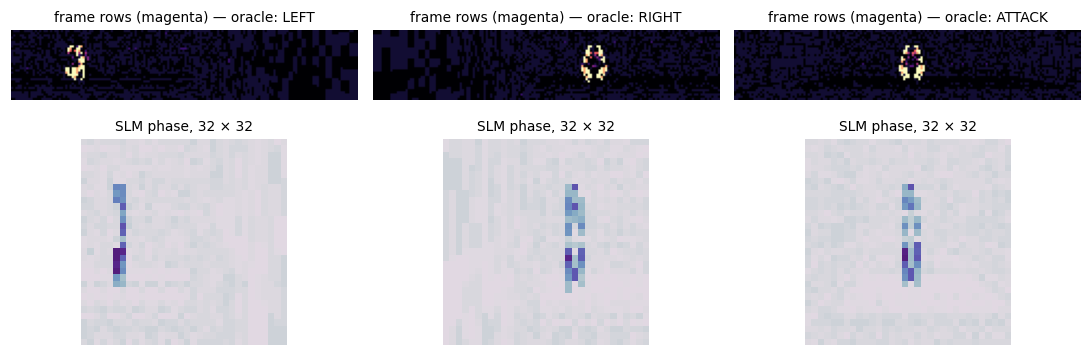

In [4]:
ACTIONS = ["LEFT", "RIGHT", "ATTACK"]


def make_game(scenario):
    game = vzd.DoomGame()
    game.load_config(os.path.join(vzd.scenarios_path, scenario + ".cfg"))
    game.set_screen_resolution(vzd.ScreenResolution.RES_160X120)
    game.set_screen_format(vzd.ScreenFormat.RGB24)
    game.set_labels_buffer_enabled(True)
    game.set_render_hud(False); game.set_render_crosshair(False); game.set_render_weapon(False)
    game.set_window_visible(False)
    game.add_available_game_variable(vzd.GameVariable.KILLCOUNT)
    game.init()
    return game


def collect(scenario, oracle, to_band, n_frames, rng):
    # a noisy oracle plays; frames the oracle can label are stored with its action
    game, bands, labels, episodes, ep = make_game(scenario), [], [], [], 0
    while len(labels) < n_frames:
        game.set_seed(ep); game.new_episode()
        held, left = 0, 0
        while not game.is_episode_finished():
            state = game.get_state()
            label = oracle(state)
            if left > 0:
                action, left = held, left - 1
            elif rng.random() < 0.1:
                held = int(rng.integers(3)); action, left = held, int(rng.integers(2, 8))
            elif label is not None and rng.random() < 0.7:
                action = label
            else:
                action = int(rng.integers(3))
            if label is not None:
                bands.append(to_band(state.screen_buffer)); labels.append(label); episodes.append(ep)
            game.make_action(np.eye(3, dtype=int)[action].tolist(), 4)
        ep += 1
    game.close()
    return np.array(bands), np.array(labels), np.array(episodes)


def make_dataset(path, bands, labels, episodes, rng, cap=False):
    # drop near-duplicates within an episode, optionally cap the classes, split the episodes 80/10/10
    cells = bands.reshape(len(bands), 32, 32, 5).mean(-1)
    keep, last = [], None
    for i in range(len(labels)):
        if last is None or episodes[i] != episodes[last] or np.mean((cells[i] - cells[last])**2) >= 4.0:
            keep.append(i); last = i
    keep = np.array(keep)
    if cap:
        n = 3 * np.bincount(labels[keep]).min()
        keep = np.sort(np.concatenate([rng.permutation(keep[labels[keep] == c])[:n] for c in range(3)]))
    order = rng.permutation(np.unique(episodes[keep]))
    part = {e: 0 if k < 0.8 * len(order) else (1 if k < 0.9 * len(order) else 2) for k, e in enumerate(order)}
    np.savez_compressed(path, band=bands[keep], labels=labels[keep], split=[part[e] for e in episodes[keep]],
                        episode=episodes[keep])


def basic_band(rgb):
    b = rgb[48:80].astype(int)
    return np.clip(6 * (b[..., 0] + b[..., 2] - 2 * b[..., 1]), 0, 255).astype(np.uint8)


def basic_error(state):
    # horizontal distance (px) of the monster from the centre of the screen, None if it is not visible
    for label in state.labels:
        if label.object_name == "Cacodemon":
            return label.x + label.width / 2 - 80
    return None


def basic_oracle(state):
    e = basic_error(state)
    return None if e is None else (2 if abs(e) <= 3.5 else (0 if e < 0 else 1))


basic_phase = lambda bands: np.pi * bands.reshape(bands.shape[:-1] + (32, 5)).mean(-1) / 255

path = os.path.join(DATA, "vizdoom_basic.npz")
if not os.path.exists(path):
    make_dataset(path, *collect("basic", basic_oracle, basic_band, 12000, np.random.default_rng(0)), np.random.default_rng(0))
data = np.load(path)
basic = dict(phi=basic_phase(data["band"]), y=data["labels"].astype(int), split=data["split"], band=data["band"],
             det=det)                                                            # the three square 24 px detectors
TRAIN, VAL, TEST = (np.nonzero(basic["split"] == k)[0] for k in range(3))
print(f"{len(basic['y'])} frames; training / validation / test = {len(TRAIN)} / {len(VAL)} / {len(TEST)}; "
      f"LEFT / RIGHT / ATTACK = {np.bincount(basic['y']).tolist()}")

fig, axs = plt.subplots(2, 3, figsize=(10, 3.4), gridspec_kw=dict(height_ratios=[1, 1.6]))
for a in range(3):
    i = TRAIN[np.nonzero(basic["y"][TRAIN] == a)[0][10]]
    axs[0, a].imshow(basic["band"][i], cmap="magma"); axs[0, a].set_title(f"frame rows (magenta) — oracle: {ACTIONS[a]}")
    axs[1, a].imshow(basic["phi"][i], cmap="twilight", vmin=0, vmax=2 * np.pi); axs[1, a].set_title("SLM phase, 32 × 32")
for a in axs.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

### Offline training

Every frame is written once with the flat reference and its field $\hat O_n$ is stored at the detector pixels: one SLM
pattern per sample, however many training steps follow. $E$ ($100\times100$, $|E|\le1$) is then trained in software on the
stored fields (`ref.train_reference`): the scores $s_c = \sum_{M_c}\mathrm{Re}(\hat O R^*)$ are linear in $E$, the loss is
the class-weighted cross-entropy plus a total-variation penalty, and the gradient $\partial L/\partial E^* =
T_R^{\mathrm H}\{\tfrac12\sum_n \hat O_n\sum_c g_{nc}M_c\}$ goes through the reference model only (30 epochs).

**Basic is read by demodulation**, as in the article (main Fig. 3c, Supplementary Note 4B): the plain reference,
trained with the recipe above (the epoch with the best validation accuracy in the model is kept), is written once, every
test frame is read once, and the action is the brightest of the three square detectors on the demodulated field
$d = OR^*$, with no offset correction. Demodulation costs only one FFT, filter and inverse FFT per frame (and one
reference-only frame); the optical inner product is unchanged. *Defend the Center* (section 4) is read all-optically,
with the fringe-matched masks on the raw frame. The curve below shows the first epoch of the training: most of the
optimization happens there.


In [5]:
def train(sc, **recipe):
    # acquire the fields once with the flat reference, then train E offline on them
    t0 = time.time()
    split = [np.nonzero(sc["split"] == k)[0] for k in range(3)]
    sc["O"] = bench.acquire(sc["phi"], detectors=sc["det"])
    sc["trace"] = []                                    # validation balanced accuracy in the first epoch
    sc["E"], sc["history"] = ref.train_reference(sc["O"][split[0]], sc["y"][split[0]], sc["O"][split[1]], sc["y"][split[1]],
                                                 sc["det"], trace=sc["trace"], **recipe)
    print(f"acquired {len(sc['y']):,} fields and trained E in {time.time() - t0:.0f} s; best validation score in the "
          f"model {sc['history'][:, 1].max():.3f}")


def test(sc, idx, E):
    # read every test frame once with E; scores, decisions and accuracy of both reads of the same frames
    y = sc["y"][idx]
    out = {}
    for name, s in zip(("raw", "demod"), bench.read(sc["phi"][idx], E, sc["det"])):
        pred = s.argmax(1)
        out[name] = dict(s=s, pred=pred, acc=np.mean(pred == y), bal=ref.balanced_accuracy(pred, y),
                         recall=np.array([np.mean(pred[y == k] == k) for k in range(3)]))
    return out


def plot_first_epoch(ax, sc, test_value, label):
    # validation balanced accuracy (in the model) from step 0 to the end of the first epoch
    steps, val = np.array(sc["trace"]).T
    ax.plot(steps, val, "o-", ms=2.5, label="validation (model)")
    ax.axhline(test_value, color="C3", ls="--", label=label)
    ax.set_xlabel("batch step (epoch 0 → 1)"); ax.set_ylabel("balanced accuracy"); ax.set_ylim(0.3, 1.01)
    ax.grid(alpha=0.3); ax.legend(fontsize=7, loc="lower right"); ax.set_title("offline training, first epoch")


bench.set_reference(ref.EXACT_REFERENCE)            # Basic: the true arm is the model (see section 2)
train(basic)
basic_test = test(basic, TEST, basic["E"])
for name, label in (("demod", "demodulated"), ("raw", "fringe-matched (raw frame)")):
    print(f"{label:27s} test accuracy {basic_test[name]['acc']:.3f} "
          f"(recall LEFT / RIGHT / ATTACK {' / '.join(f'{v:.2f}' for v in basic_test[name]['recall'])})")
print(f"flat reference: {np.mean(bench.read(basic['phi'][TEST], ref.FLAT, basic['det'])[1].argmax(1) == basic['y'][TEST]):.3f}")

acquired 9,996 fields and trained E in 344 s; best validation score in the model 0.970


demodulated                 test accuracy 0.971 (recall LEFT / RIGHT / ATTACK 0.98 / 0.97 / 0.90)
fringe-matched (raw frame)  test accuracy 0.971 (recall LEFT / RIGHT / ATTACK 0.99 / 0.96 / 0.92)


flat reference: 0.315


**Agreement of the two reads** (cf. Fig. S3b): the scores of the same test frames, each z-scored, and how often the two
reads take the same decision.

**Digital baselines** on the same $32\times32$ encoded inputs (scaled to 0–1), as on the bench:

* a **linear classifier**: class-balanced logistic regression, with the L2 strength $C \in \{0.01, 0.1, 1, 10\}$ chosen on
  the validation frames;
* a **small CNN**: two 3 × 3 convolutions (8 and 16 channels), each followed by ReLU and 2 × 2 max pooling, a 64-unit
  hidden layer and three outputs; class-weighted cross-entropy, Adam (learning rate 2·10⁻³, cosine schedule, batches of 64),
  30 epochs, the epoch with the best validation accuracy is kept.


fringe-matched vs demodulated scores: r = 0.9999, 0.9998, 0.9995; same decision on 99.2 % of the test frames
test accuracy: optical (demodulated) 0.971, digital CNN 0.999, digital linear classifier 0.998


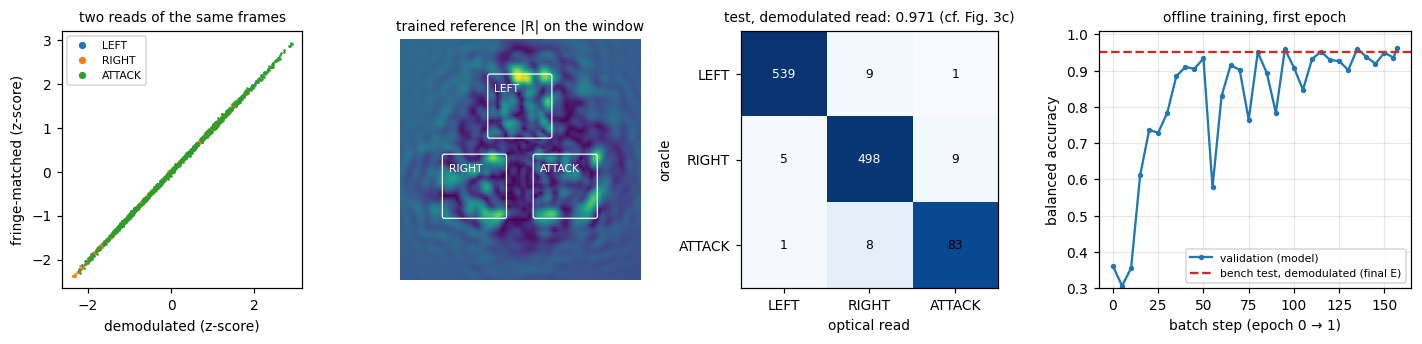

In [6]:
import scipy.optimize
import torch


def logistic_regression(X, y, C):
    # class-balanced multinomial logistic regression: sum_n w_n CE_n + |W|^2 / (2C), intercept not penalised
    n, f = X.shape
    w = (len(y) / (3 * np.bincount(y, minlength=3)))[y]

    def loss(p):
        W, b = p[:3 * f].reshape(f, 3), p[3 * f:]
        z = X @ W + b
        z = z - z.max(1, keepdims=True)
        P = np.exp(z); P /= P.sum(1, keepdims=True)
        G = w[:, None] * (P - np.eye(3)[y])
        L = -np.sum(w * np.log(P[np.arange(n), y] + 1e-300)) + np.sum(W * W) / (2 * C)
        return L, np.concatenate([(X.T @ G + W / C).ravel(), G.sum(0)])
    p = scipy.optimize.minimize(loss, np.zeros(3 * f + 3), jac=True, method="L-BFGS-B", options=dict(maxiter=3000)).x
    W, b = p[:3 * f].reshape(f, 3), p[3 * f:]
    return lambda X_new: (X_new @ W + b).argmax(1)


def linear_classifier(X, y, X_val, y_val):
    # the bench's digital linear baseline: C chosen on the validation frames
    models = [logistic_regression(X, y, C) for C in (0.01, 0.1, 1.0, 10.0)]
    return max(models, key=lambda m: np.mean(m(X_val) == y_val))


def cnn_classifier(phi, y, phi_val, y_val, epochs=30, lr=2e-3, batch=64, seed=0):
    # the bench's small CNN on the encoded 32 x 32 inputs (phase / pi, 0..1)
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    nn = torch.nn
    net = nn.Sequential(nn.Conv2d(1, 8, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                        nn.Conv2d(8, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                        nn.Flatten(), nn.Linear(16 * 8 * 8, 64), nn.ReLU(), nn.Linear(64, 3))
    to_x = lambda p: torch.tensor(p[:, None] / np.pi, dtype=torch.float32)
    X, Y, X_val = to_x(phi), torch.tensor(y), to_x(phi_val)
    weights = torch.tensor(len(y) / (3 * np.bincount(y, minlength=3)), dtype=torch.float32)
    loss = nn.CrossEntropyLoss(weight=weights)
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    schedule = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    best = (-1, None)
    for epoch in range(epochs):
        net.train()
        order = rng.permutation(len(y))
        for b in range(0, len(y), batch):
            ids = order[b:b + batch]
            opt.zero_grad(); loss(net(X[ids]), Y[ids]).backward(); opt.step()
        schedule.step()
        net.eval()
        with torch.no_grad():
            val = np.mean(net(X_val).argmax(1).numpy() == y_val)
        if val > best[0]:
            best = (val, {k: v.clone() for k, v in net.state_dict().items()})
    net.load_state_dict(best[1]); net.eval()

    def predict(p):
        with torch.no_grad():
            return net(to_x(p)).argmax(1).numpy()
    return predict


features = lambda phi: phi.reshape(len(phi), -1) / np.pi                     # the encoded values, 0..1
basic_linear = linear_classifier(features(basic["phi"][TRAIN]), basic["y"][TRAIN],
                                 features(basic["phi"][VAL]), basic["y"][VAL])
acc_linear = np.mean(basic_linear(features(basic["phi"][TEST])) == basic["y"][TEST])
basic_cnn = cnn_classifier(basic["phi"][TRAIN], basic["y"][TRAIN], basic["phi"][VAL], basic["y"][VAL])
acc_cnn = np.mean(basic_cnn(basic["phi"][TEST]) == basic["y"][TEST])

z = lambda s: (s - s.mean(0)) / s.std(0)
r = [np.corrcoef(basic_test["raw"]["s"][:, k], basic_test["demod"]["s"][:, k])[0, 1] for k in range(3)]
same = np.mean(basic_test["raw"]["pred"] == basic_test["demod"]["pred"])
print(f"fringe-matched vs demodulated scores: r = {', '.join(f'{v:.4f}' for v in r)}; same decision on {100 * same:.1f} % "
      f"of the test frames")
print(f"test accuracy: optical (demodulated) {basic_test['demod']['acc']:.3f}, digital CNN {acc_cnn:.3f}, "
      f"digital linear classifier {acc_linear:.3f}")

fig, axs = plt.subplots(1, 4, figsize=(13, 3.2), gridspec_kw=dict(width_ratios=[1, 1, 1.1, 1.3]))
for k in range(3):
    axs[0].plot(z(basic_test["demod"]["s"])[:, k], z(basic_test["raw"]["s"])[:, k], ".", ms=1.5, label=ACTIONS[k])
axs[0].set_xlabel("demodulated (z-score)"); axs[0].set_ylabel("fringe-matched (z-score)"); axs[0].legend(fontsize=7, markerscale=5)
axs[0].set_title("two reads of the same frames")
axs[1].imshow(np.abs(bench._ref.forward(ref.slm_response(basic["E"]))[ref.W90, ref.W90]), cmap="viridis")
axs[1].contour(basic["det"].window.max(0), levels=[0.5], colors="w", linewidths=0.8)
for k, (rr, cc) in enumerate(det.corners):
    axs[1].text(cc + 2, rr + 6, ACTIONS[k], color="w", fontsize=7)
axs[1].set_title("trained reference |R| on the window"); axs[1].axis("off")
cm = np.zeros((3, 3))
for t, p in zip(basic["y"][TEST], basic_test["demod"]["pred"]): cm[t, p] += 1
axs[2].imshow(cm / cm.sum(1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
for i in range(3):
    for j in range(3): axs[2].text(j, i, int(cm[i, j]), ha="center", va="center", fontsize=8, color="w" if cm[i, j] > cm.max() / 2 else "k")
axs[2].set_xticks(range(3)); axs[2].set_xticklabels(ACTIONS); axs[2].set_yticks(range(3)); axs[2].set_yticklabels(ACTIONS)
axs[2].set_xlabel("optical read"); axs[2].set_ylabel("oracle")
axs[2].set_title(f"test, demodulated read: {basic_test['demod']['acc']:.3f} (cf. Fig. 3c)")
plot_first_epoch(axs[3], basic, basic_test["demod"]["bal"], "bench test, demodulated (final E)")
plt.tight_layout(); plt.show()

### Closed loop

The bench plays: every game frame is encoded, written on the object arm, read **once** with the trained reference
(demodulated read, plain reference), and the brightest detector is the action (four game tics per action). 100
episodes on seeds never used for the data; an episode is won when the monster dies before the timeout. The oracle, the
two digital baselines and a random policy play the same seeds. The GIF shows one episode as the bench plays it: the game,
the phase written on the object arm, and the demodulated camera field with the chosen detector.


policy              won  steps to kill
optical (bench)  100/100           8.59
oracle           100/100           7.42
digital CNN      100/100           7.44
digital linear   100/100           7.40
random            50/100          30.98
paired difference optical - oracle: +1.17 ± 0.30 steps (on 100 episodes both won)


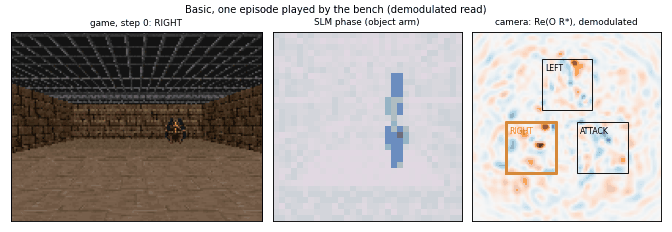

In [7]:
def optical_policy(sc, encode, read="raw"):
    # one bench read per game frame with the scenario's E and detectors; the brightest detector of the chosen read
    k = 0 if read == "raw" else 1

    def act(state):
        x = encode(state.screen_buffer)
        s = bench.read(x, sc["E"], sc["det"])[k][0]
        act.last = (x[0], bench.last_frame, s)                # SLM phase, camera frame and scores, for the GIF
        return int(np.argmax(s))
    return act


def play(scenario, policy, seeds, record=False):
    # kills and steps per episode; with record, also every step of the first episode (for the GIF)
    game, kills, steps, frames = make_game(scenario), [], [], []
    for s in seeds:
        game.set_seed(int(s)); game.new_episode()
        n = 0
        while not game.is_episode_finished():
            state = game.get_state()
            action = policy(state)
            if record and s == seeds[0]:
                frames.append((state.screen_buffer.copy(), *policy.last, action))
            game.make_action(np.eye(3, dtype=int)[action].tolist(), 4)
            n += 1
        kills.append(game.get_game_variable(vzd.GameVariable.KILLCOUNT)); steps.append(n)
    game.close()
    return dict(kills=np.array(kills), steps=np.array(steps), frames=frames)


rng_play = np.random.default_rng(0)
seeds = np.arange(1_000_000, 1_000_100)
basic_encode = lambda rgb: basic_phase(basic_band(rgb)[None])
policies = {"optical (bench)": optical_policy(basic, basic_encode, read="demod"),
            "oracle": lambda st: basic_oracle(st) if basic_oracle(st) is not None else int(rng_play.integers(3)),
            "digital CNN": lambda st: int(basic_cnn(basic_encode(st.screen_buffer))[0]),
            "digital linear": lambda st: int(basic_linear(features(basic_encode(st.screen_buffer)))[0]),
            "random": lambda st: int(rng_play.integers(3))}
basic_loop = {name: play("basic", pol, seeds, record=name == "optical (bench)") for name, pol in policies.items()}
won = {name: r["kills"] > 0 for name, r in basic_loop.items()}
both = won["optical (bench)"] & won["oracle"]
diff = basic_loop["optical (bench)"]["steps"][both] - basic_loop["oracle"]["steps"][both]
print(f"{'policy':16s} {'won':>6s} {'steps to kill':>14s}")
for name, r in basic_loop.items():
    print(f"{name:16s} {won[name].sum():3d}/100 {r['steps'][won[name]].mean():14.2f}")
print(f"paired difference optical - oracle: {diff.mean():+.2f} ± {diff.std(ddof=1) / np.sqrt(len(diff)):.2f} steps "
      f"(on {both.sum()} episodes both won)")

ref.save_episode_gif("gifs/vizdoom_basic_episode.gif", basic_loop["optical (bench)"]["frames"], basic["det"], "demod",
                     "Basic, one episode played by the bench (demodulated read)", fps=3)
display(Image(filename="gifs/vizdoom_basic_episode.gif"))


## 4 · *Defend the Center*

Monsters approach from all sides; the player turns left or right and shoots. The oracle turns toward the largest
monster in view, shoots when it is centred, and turns left when nothing is in view.

* **Encoding** (fixed, no learned features): rows 44–75 projected on fixed colour weights that separate the monsters from
  the walls, then the maximum of each 1 × 5 block and of each column, written to all 32 rows: the horizontal position of
  the monsters, which decides the action, is what reaches the SLM.
* **Data**: as for *Basic*, with the classes capped (cached in `vizdoom_defend_the_center.npz`).

The reference is trained offline exactly as for *Basic*. *Defend the Center* is read **all-optically**: one raw-frame
read per step with the fringe-matched masks, no Fourier transform, and the brightest detector is the action, with the
plain reference (no offset correction on the test frames). The bench plays 30 episodes on the bench's seeds (1,000,000–1,000,029); the
score is the number of kills per episode (mean ± s.e.m.), against the oracle, the two digital baselines of section 3
retrained on these inputs, and random actions (Fig. 3d). The baselines play first; the bench's episodes follow
below, with its detector offsets.


10000 frames; training / validation / test = 8059 / 833 / 1108


acquired 10,000 fields and trained E in 338 s; best validation score in the model 0.820


optical, all-optical (raw frame)  test accuracy 0.772, balanced 0.797
optical, demodulated              test accuracy 0.775, balanced 0.803
digital CNN                       test accuracy 0.841, balanced 0.851
digital linear                    test accuracy 0.777, balanced 0.790


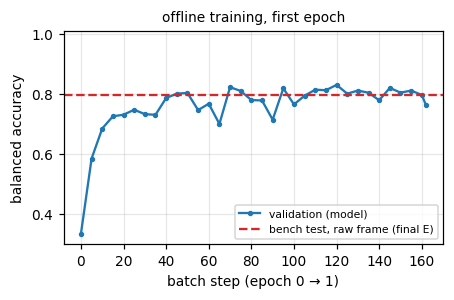

In [8]:
LDA, LO, HI = np.array([0.18311, -0.57792, 0.23897]), -9.1941, 14.2908
TARGETS = ("MarineChainsawVzd", "Demon")


def dtc_band(rgb):
    p = rgb[44:76].astype(float) @ LDA
    return np.clip(np.round(255 * (p - LO) / (HI - LO)), 0, 255).astype(np.uint8)


def dtc_oracle(state):
    best = None
    for label in state.labels:
        if label.object_name in TARGETS and label.width >= 1 and label.height >= 0.8 * label.width \
                and (best is None or label.height > best.height):
            best = label
    if best is None:
        return 0
    e = best.x + best.width / 2 - 80
    return 2 if abs(e) <= max(1, 0.5 * best.width) else (0 if e < 0 else 1)


def dtc_phase(bands):
    column = bands.reshape(bands.shape[:-1] + (32, 5)).max(-1).max(-2)                 # one value per column
    return np.pi * np.repeat(column[..., None, :], 32, axis=-2) / 255


path = os.path.join(DATA, "vizdoom_defend_the_center.npz")
if not os.path.exists(path):
    make_dataset(path, *collect("defend_the_center", dtc_oracle, dtc_band, 16000, np.random.default_rng(0)),
                 np.random.default_rng(0), cap=True)
data = np.load(path)
dtc = dict(phi=dtc_phase(data["band"]), y=data["labels"].astype(int), split=data["split"], band=data["band"],
           det=det)                                                            # hard 24 px boxes, as in that run
D_TRAIN, D_VAL, D_TEST = (np.nonzero(dtc["split"] == k)[0] for k in range(3))
print(f"{len(dtc['y'])} frames; training / validation / test = {len(D_TRAIN)} / {len(D_VAL)} / {len(D_TEST)}")

bench.set_reference(ref.TRUE_REFERENCE)             # Defend the Center: the hidden arm of section 2
train(dtc)
dtc_test = test(dtc, D_TEST, dtc["E"])                                   # plain reference
dtc_linear = linear_classifier(features(dtc["phi"][D_TRAIN]), dtc["y"][D_TRAIN], features(dtc["phi"][D_VAL]), dtc["y"][D_VAL])
dtc_cnn = cnn_classifier(dtc["phi"][D_TRAIN], dtc["y"][D_TRAIN], dtc["phi"][D_VAL], dtc["y"][D_VAL])
y_test = dtc["y"][D_TEST]
for name, label in (("raw", "optical, all-optical (raw frame)"), ("demod", "optical, demodulated")):
    print(f"{label:33s} test accuracy {dtc_test[name]['acc']:.3f}, balanced {dtc_test[name]['bal']:.3f}")
for label, pred in (("digital CNN", dtc_cnn(dtc["phi"][D_TEST])), ("digital linear", dtc_linear(features(dtc["phi"][D_TEST])))):
    print(f"{label:33s} test accuracy {np.mean(pred == y_test):.3f}, balanced {ref.balanced_accuracy(pred, y_test):.3f}")

fig, ax = plt.subplots(figsize=(4.2, 2.8))
plot_first_epoch(ax, dtc, dtc_test["raw"]["bal"], "bench test, raw frame (final E)")
plt.tight_layout(); plt.show()

In [9]:
dtc_encode = lambda rgb: dtc_phase(dtc_band(rgb)[None])
seeds = np.arange(1_000_000, 1_000_030)
policies = {"oracle": dtc_oracle,
            "digital CNN": lambda st: int(dtc_cnn(dtc_encode(st.screen_buffer))[0]),
            "digital linear": lambda st: int(dtc_linear(features(dtc_encode(st.screen_buffer)))[0]),
            "random": lambda st: int(rng_play.integers(3))}
dtc_loop = {name: play("defend_the_center", pol, seeds) for name, pol in policies.items()}
sem = lambda v: np.std(v, ddof=1) / np.sqrt(len(v))
print(f"{'policy':30s} kills per episode (30 unseen seeds)")
for name, r in dtc_loop.items():
    print(f"{name:30s} {r['kills'].mean():5.2f} ± {sem(r['kills']):.2f}")


policy                         kills per episode (30 unseen seeds)
oracle                         15.40 ± 1.06
digital CNN                    12.53 ± 0.91
digital linear                  3.53 ± 0.58
random                          1.63 ± 0.24


### Closed loop with the bench's detector offsets

On the bench, the three detectors carried slightly different offsets than the model predicts, strongest on dim frames,
where they tipped the decision toward RIGHT. With nothing in view the scores are close, so this lean kept the bench
turning one way to find the next monster, while frames with a monster in view were decided by the trained reference. The
twin's detectors have no such lean, so we add the bench's measured offsets here to reproduce the bench's closed-loop
behaviour; the reference and the read are unchanged. The digital baselines get no offset, since the offset is a
property of the optical read.


In [10]:
# offsets of the bench's raw read relative to its own model (2026-10-25 run), in score spreads, per detector L/R/A
BENCH_OFFSET = {"dim": np.array([-0.33, 0.22, 0.11]), "other": np.array([-0.25, 0.09, 0.16])}
DIM = 60                                                   # brightest column below 60 of 255: nothing in view


def kind(phase):
    return "dim" if phase.max() * 255 / np.pi < DIM else "other"


# the twin's own offsets in the same units, so that the twin ends up with the bench's offsets
det_d = dtc["det"]
s_twin = dtc_test["raw"]["s"]
s_model = det_d.scores(dtc["O"][D_TEST], det_d.on_pixels(ref.MODEL.forward(dtc["E"])))
scale = np.sum((s_twin - s_twin.mean()) * (s_model - s_model.mean())) / np.sum((s_model - s_model.mean()) ** 2)
residual = (s_twin / scale - s_model) / s_model.std()
kinds = np.array([kind(p) for p in dtc["phi"][D_TEST]])
shift = {}
for k in ("dim", "other"):
    own = residual[kinds == k].mean(0)
    own = own - own.mean()
    shift[k] = (BENCH_OFFSET[k] - own) * scale * s_model.std()
    print(f"{k:5s} frames ({np.mean(kinds == k):.0%} of test): twin offset {np.round(own, 2)}, bench {BENCH_OFFSET[k]}")

y_test = dtc["y"][D_TEST]
pred = np.array([np.argmax(s + shift[k]) for s, k in zip(s_twin, kinds)])
for name, p in (("twin, plain", s_twin.argmax(1)), ("twin + bench offsets", pred)):
    dim_share = np.bincount(p[kinds == "dim"], minlength=3) / np.sum(kinds == "dim")
    print(f"test, {name:22s} accuracy {np.mean(p == y_test):.3f}, balanced {ref.balanced_accuracy(p, y_test):.3f}, "
          f"dim frames L/R/A {np.round(dim_share, 2)}")


def offset_policy(state):
    x = dtc_encode(state.screen_buffer)
    s = bench.read(x, dtc["E"], det_d)[0][0] + shift[kind(x)]
    offset_policy.last = (x[0], bench.last_frame, s)          # for the GIF
    return int(np.argmax(s))


dtc_loop["optical (bench)"] = play("defend_the_center", offset_policy, seeds, record=True)
k, lin = dtc_loop["optical (bench)"]["kills"], dtc_loop["digital linear"]["kills"]
print(f"\nkills per episode (the same 30 seeds): optical {k.mean():.2f} ± {sem(k):.2f}, linear {lin.mean():.2f}; "
      f"bench 7.87 ± 0.93")
print(f"paired: optical - linear {np.mean(k - lin):+.2f} ± {sem(k - lin):.2f}")

ref.save_episode_gif("gifs/vizdoom_defend_the_center_episode.gif", dtc_loop["optical (bench)"]["frames"], dtc["det"], "raw",
                     "Defend the Center, one episode played by the bench (all-optical read)", fps=6)


dim   frames (4% of test): twin offset [-0.18  0.09  0.1 ], bench [-0.33  0.22  0.11]
other frames (96% of test): twin offset [-0.14  0.07  0.07], bench [-0.25  0.09  0.16]
test, twin, plain            accuracy 0.772, balanced 0.797, dim frames L/R/A [0.37 0.63 0.  ]
test, twin + bench offsets   accuracy 0.760, balanced 0.795, dim frames L/R/A [0.08 0.92 0.  ]



kills per episode (the same 30 seeds): optical 6.90 ± 0.92, linear 3.53; bench 7.87 ± 0.93
paired: optical - linear +3.37 ± 0.92


One episode of *Defend the Center* played by the bench (linked GIF, `gifs/vizdoom_defend_the_center_episode.gif`):

![Defend the Center](gifs/vizdoom_defend_the_center_episode.gif)

## Summary: the twin next to the bench

The bench values are those of the article: *Basic* with the plain reference read by demodulation (main Fig. 3c and main
text), *Defend the Center* with the plain reference read all-optically from the raw frame (main Fig. 3d, Supplementary
Note 4B). The twin's oracle scores more kills than the bench's on the same seeds because the bench's game build replayed
the same game on 14 of its 30 seeds, so the two oracles play partly different games.


In [11]:
rows = [
    ("reference-model accuracy (check probes)", f"{np.mean(accuracy):.3f}", "0.854"),
    ("Basic: test, optical (demodulated read)", f"{basic_test['demod']['acc']:.3f}", "0.987"),
    ("Basic: recall LEFT / RIGHT / ATTACK", " / ".join(f"{v:.2f}" for v in basic_test["demod"]["recall"]), "1.00 / 0.98 / 0.98"),
    ("Basic: test, digital CNN", f"{acc_cnn:.3f}", "0.999"),
    ("Basic: test, digital linear", f"{acc_linear:.3f}", "—"),
    ("Basic: closed loop, episodes won", f"{won['optical (bench)'].sum()}/100", "100/100"),
    ("Basic: closed loop, steps optical - oracle", f"{diff.mean():+.2f}", "about +1"),
    ("Defend the Center: test, optical (raw frame)", f"{dtc_test['raw']['acc']:.3f}", "0.718"),
]
for name, key, b in [("optical (bench offsets)", "optical (bench)", "7.87 ± 0.93"),
                     ("digital CNN", "digital CNN", "10.67 ± 0.63"), ("digital linear", "digital linear", "3.50 ± 0.70"),
                     ("random", "random", "1.37 ± 0.20"), ("oracle", "oracle", "12.03 ± 0.74")]:
    k = dtc_loop[key]["kills"]
    rows.append((f"Defend the Center: kills, {name}", f"{k.mean():.2f} ± {sem(k):.2f}", b))
print(f"{'':50s} {'twin':>14s} {'bench':>14s}")
for name, t, b in rows:
    print(f"{name:50s} {t:>14s} {b:>14s}")
print(f"\nbench reads in the twin: {bench.reads:,}; diffuser probes: 0; runtime {time.time() - T_START:.0f} s")


                                                             twin          bench
reference-model accuracy (check probes)                     0.973          0.854
Basic: test, optical (demodulated read)                     0.971          0.987
Basic: recall LEFT / RIGHT / ATTACK                0.98 / 0.97 / 0.90 1.00 / 0.98 / 0.98
Basic: test, digital CNN                                    0.999          0.999
Basic: test, digital linear                                 0.998              —
Basic: closed loop, episodes won                          100/100        100/100
Basic: closed loop, steps optical - oracle                  +1.17       about +1
Defend the Center: test, optical (raw frame)                0.772          0.718
Defend the Center: kills, optical (bench offsets)     6.90 ± 0.92    7.87 ± 0.93
Defend the Center: kills, digital CNN                12.53 ± 0.91   10.67 ± 0.63
Defend the Center: kills, digital linear              3.53 ± 0.58    3.50 ± 0.70
Defend the Center: k

**Take-aways.** The diffuser is never modelled and never probed: the object fields are measured once with a flat
reference, and the reference is trained offline through a model of its own free-space path; most of the training happens
in the first epoch. In *Basic*, the plain reference read by demodulation with the three square detectors classifies test
frames with 0.971 accuracy (digital CNN 0.999, linear 0.998; bench 0.987), and in closed loop it wins all 100 unseen
episodes, about one step slower than the oracle (+1.17 steps), as on the bench. The fringe-matched read of the raw frame
gives the same scores (r ≥ 0.999) and the same decision on 99 % of the frames. In *Defend the Center*, read
all-optically from the raw frame, the plain reference classifies test frames as well as the linear classifier (balanced
0.797 against 0.790) and, with the bench's measured detector offsets, kills 6.9 ± 0.9 enemies per episode, against 7.87 ± 0.93 on the bench, 3.5 for the linear classifier and 12.5 for the CNN.
